### Preference-Based Recommendation Using User-Based Collaborative Filtering

The existing recommendation approach focuses on product popularity and average ratings. To provide more personalized recommendations, this model uses **User-Based Collaborative Filtering with Cosine Similarity** to identify users with similar product-rating patterns.

The model follows these steps:

1. **User–Item Matrix:** Creates a matrix containing users, products, and their ratings.
2. **Cosine Similarity:** Calculates similarity between the target user and other users based on their rating patterns.
3. **Similar User Selection:** Selects the top 20 most similar users to identify relevant product preferences.
4. **Candidate Product Selection:** Finds products rated by similar users but not yet rated by the target user.
5. **Rating Prediction:** Calculates predicted ratings using a similarity-weighted average of ratings provided by similar users.
6. **Recommendation Generation:** Ranks candidate products by predicted rating and recommends the highest-ranked products to the target user.

### Key Advantage

Unlike popularity-based recommendations, this approach considers individual user preferences. Different users can receive different recommendations because the model uses the ratings of users with similar interests.

### Model Evaluation

The model is evaluated using **Mean Squared Error (MSE)** and **Root Mean Squared Error (RMSE)** on eligible held-out test ratings. These metrics measure the difference between actual ratings and predicted ratings, with lower values indicating better prediction accuracy.

* Please note Section 1 and 2 are same for the prefernece and popularity based model files with only differnece that we took a larger subset of 3000000

# Section - 1 (Importing The data)

In [15]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("saurav9786/amazon-product-reviews")

In [16]:
#import the reqired libraries
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
import joblib 
import scipy.sparse
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
import warnings; warnings.simplefilter('ignore')

#Importing Surprise and relevant packages to do some hyper parameter tuning through Grid Search
from surprise import Dataset
from surprise import Reader
from surprise.model_selection import cross_validate
from surprise.model_selection import GridSearchCV
from surprise import KNNBasic, KNNWithMeans, KNNWithZScore
from surprise import SVD, SVDpp, NMF
from surprise import SlopeOne, CoClustering
# %matplotlib inline

In [17]:
path = path+"\\ratings_Electronics (1).csv"
columns = ['userId', 'productId', 'rating', 'timestamp']
dataset = pd.read_csv(path, names=columns, header=0)
dataset.head()

,userId,productId,rating,timestamp
0,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
1,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
2,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
3,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200
4,A1QGNMC6O1VW39,0511189877,5.0,1397433600


In [18]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 7824481 entries, 0 to 7824480
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     str    
 1   productId  str    
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 238.8 MB


In [19]:
print('Number of missing values across columns: \n',dataset.isnull().sum())


Number of missing values across columns: 
 userId       0
productId    0
rating       0
timestamp    0
dtype: int64


In [20]:
#Checking the number of rows and columns
rows,columns=dataset.shape
print('Number of rows: ',rows)
print('Number of columns: ',columns)

Number of rows:  7824481
Number of columns:  4


##### So There are no missing records in the dataset

# Section-2 (Analyzing the Data)

array([[<Axes: title={'center': 'rating'}>,
        <Axes: title={'center': 'timestamp'}>]], dtype=object)

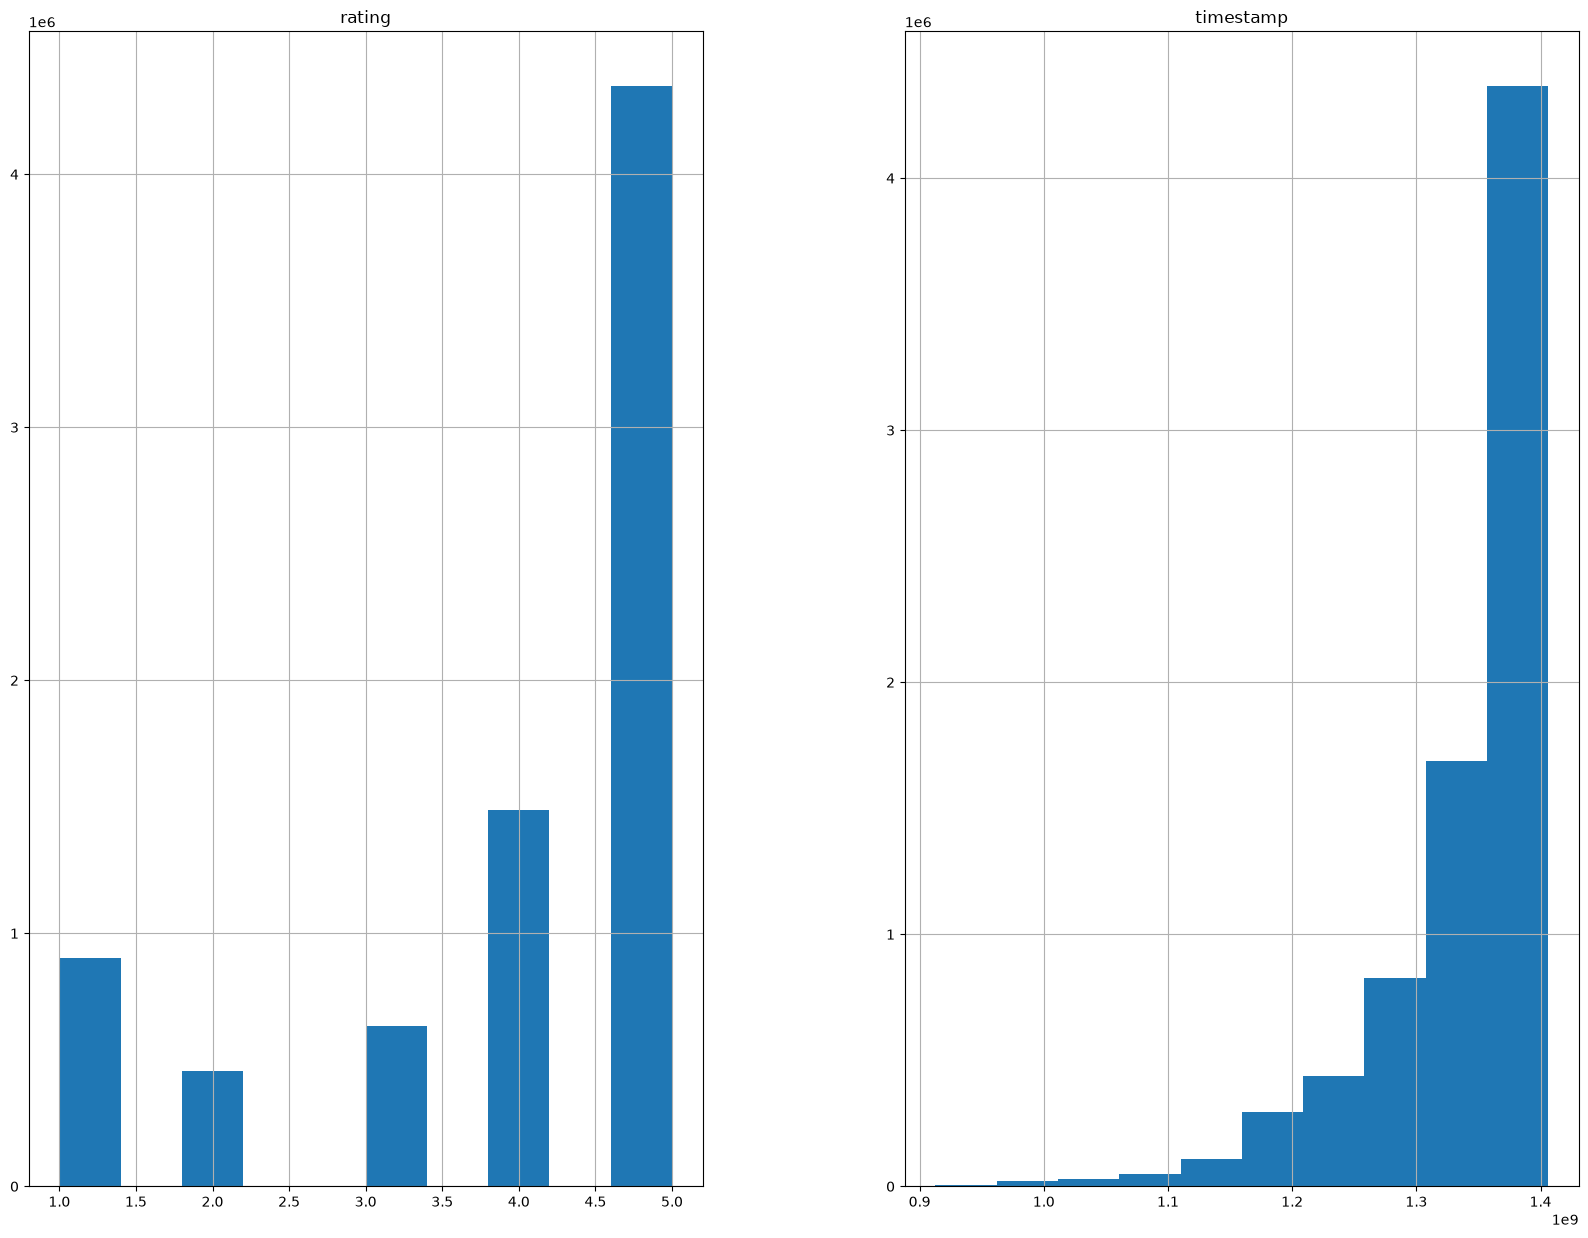

In [21]:
dataset.hist(figsize=(20, 15))
plt.show()

#### Removing the timestamp attribute as it is not required for our analysis

In [22]:
dataset.drop('timestamp',axis=1,inplace=True)

In [23]:
print("Electronic Data Summary")
print("="*100)
print("\nTotal # of Ratings :",dataset.shape[0])
print("Total # of Users   :", len(np.unique(dataset.userId)))
print("Total # of Products  :", len(np.unique(dataset.productId)))
print("\n")
print("="*100)

Electronic Data Summary

Total # of Ratings : 7824481
Total # of Users   : 4201696
Total # of Products  : 476001




### The Dataset is very Large with more no. of users than no. of products so lets consider a new dataset of a smaller size

In [24]:
datasubset = dataset.iloc()[:3000000, :]
datasubset.shape

(3000000, 3)

In [25]:
datasubset.head()

,userId,productId,rating
0,A2CX7LUOHB2NDG,0321732944,5.0
1,A2NWSAGRHCP8N5,0439886341,1.0
2,A2WNBOD3WNDNKT,0439886341,3.0
3,A1GI0U4ZRJA8WN,0439886341,1.0
4,A1QGNMC6O1VW39,0511189877,5.0


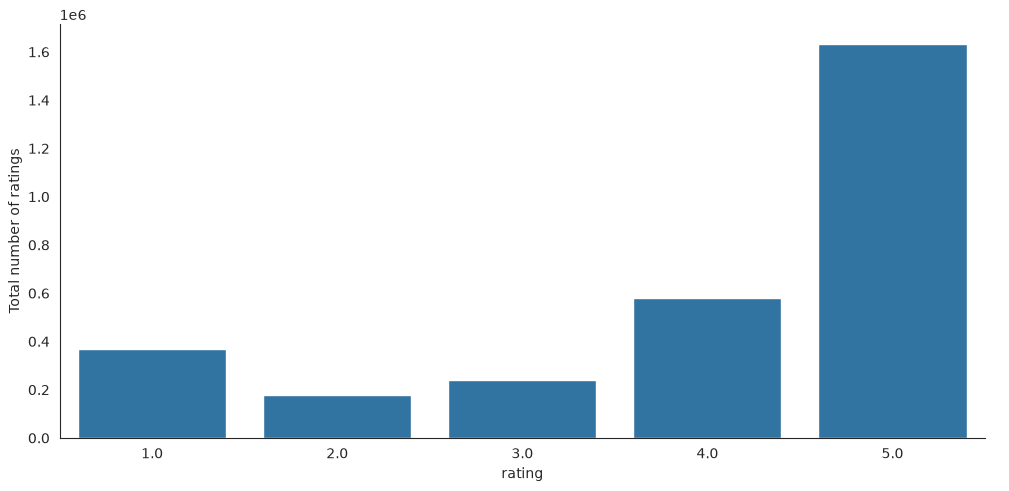

In [26]:
# Check the distribution of the rating
with sns.axes_style('white'):
    g = sns.catplot(x="rating", data=datasubset, aspect=2.0, kind='count')
    g.set_ylabels("Total number of ratings")


<Axes: ylabel='rating'>

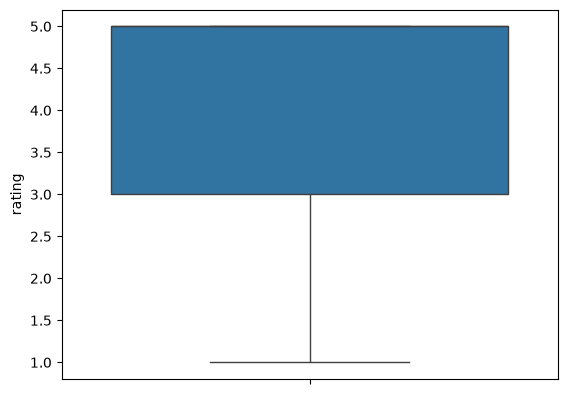

In [27]:
sns.boxplot(y='rating',data=datasubset)

### As we can see most of the ratings lie between 3 to 5

### Now lets check no. of products a customer has rated

In [28]:
datasubset.drop_duplicates(inplace=True)
most_rated=datasubset.groupby('userId').size().sort_values(ascending=False)
print('Users based on ratings: \n',most_rated)

Users based on ratings: 
 userId
A5JLAU2ARJ0BO     465
A6FIAB28IS79      325
A3OXHLG6DIBRW8    303
A231WM2Z2JL0U3    252
A680RUE1FDO8B     227
                 ... 
AZZY3B308E3UB       1
AZZXZ9EX2JCFJ       1
AZZXYSVQWI7D7       1
AZZXOJ1U9O5HV       1
AZZX3COL525E6       1
Length: 1928028, dtype: int64


In [29]:
counts=datasubset.userId.value_counts()
datasubset_final=datasubset[datasubset.userId.isin(counts[counts>=10].index)]
print('Number of users who have rated 10 or more items =', len(datasubset_final))
print('Number of unique users in the final data = ', datasubset_final['userId'].nunique())
print('Number of unique products in the final data = ', datasubset_final['productId'].nunique())

Number of users who have rated 10 or more items = 224243
Number of unique users in the final data =  13808
Number of unique products in the final data =  57394


* datasubset_final has the users who have rated 10 or more items. Because users who haven't used much products shouldn't be accounted for.

In [30]:
#statistical analysis of the most rated user data
most_rated.describe().astype(int).T

count    1928028
mean           1
std            1
min            1
25%            1
50%            1
75%            1
max          465
dtype: int64

Text(0.5, 1.0, '# RATINGS per Product')

Text(0.5, 0, 'Product')

Text(0, 0.5, '# ratings per product')

[Text(-10000.0, 0, ''),
 Text(0.0, 0, ''),
 Text(10000.0, 0, ''),
 Text(20000.0, 0, ''),
 Text(30000.0, 0, ''),
 Text(40000.0, 0, ''),
 Text(50000.0, 0, ''),
 Text(60000.0, 0, ''),
 Text(70000.0, 0, '')]

<function matplotlib.pyplot.show(close=None, block=None)>

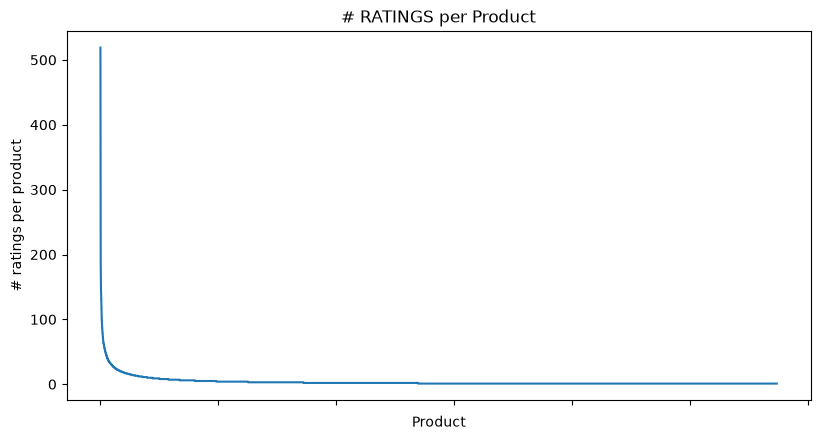

In [31]:
#Products also have skewed ratings with majority of the products having very few ratings
no_of_ratings_per_product = datasubset_final.groupby(by='productId')['rating'].count().sort_values(ascending=False)

fig = plt.figure(figsize=plt.figaspect(.5))
ax = plt.gca()
plt.plot(no_of_ratings_per_product.values)
plt.title('# RATINGS per Product')
plt.xlabel('Product')
plt.ylabel('# ratings per product')
ax.set_xticklabels([])

plt.show

In [32]:
ratings_mean_count = pd.DataFrame(datasubset_final.groupby('productId')['rating'].mean())
ratings_mean_count['rating_counts'] = pd.DataFrame(datasubset_final.groupby('productId')['rating'].count())
ratings_mean_count.head()




,rating,rating_counts
productId,,
0511189877,2.000000,1
0594451647,5.000000,1
0594481813,3.000000,2
0970407998,2.500000,2
0972683275,4.535714,28


In [34]:
#The maximum number of ratings received for a product is 519

ratings_mean_count['rating_counts'].max()

np.int64(519)

<Figure size 800x600 with 0 Axes>

<Axes: >

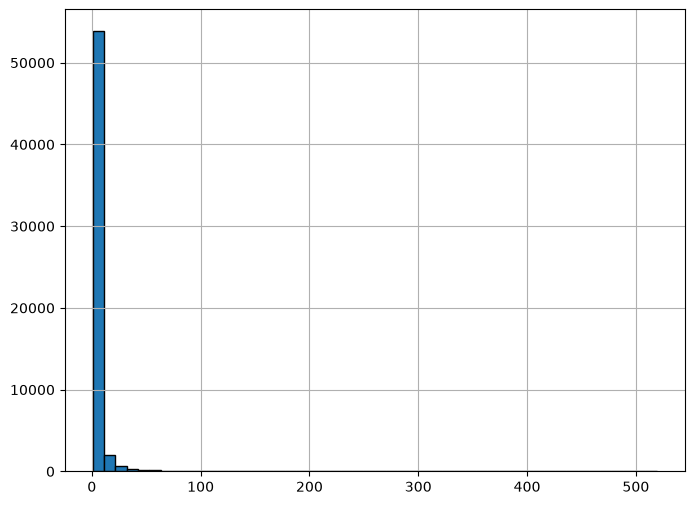

In [35]:
#### Majority of the products have received 1 rating only and it is a right skewed distribution
plt.figure(figsize=(8,6))
plt.rcParams['patch.force_edgecolor'] = True
ratings_mean_count['rating_counts'].hist(bins=50)

<Figure size 800x600 with 0 Axes>

<Axes: >

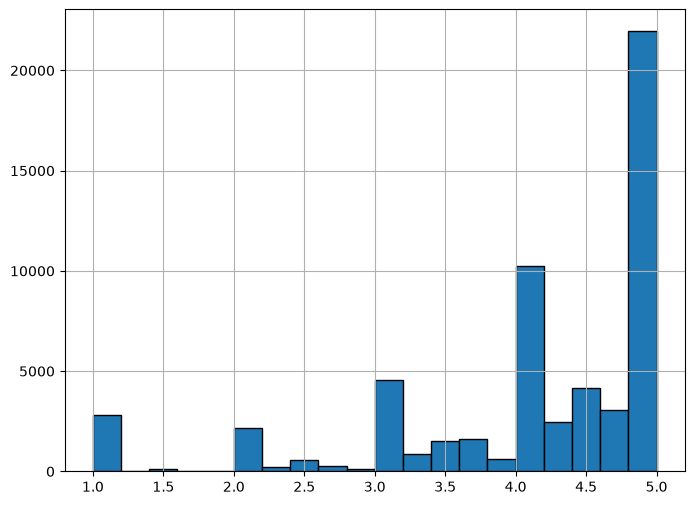

In [36]:
#We see a left skewed distribution for the ratings
#There are clusters at each of the points 1,2,3,4,5 as that is where the means are concentrated
plt.figure(figsize=(8,6))
plt.rcParams['patch.force_edgecolor'] = True
ratings_mean_count['rating'].hist(bins=20)

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

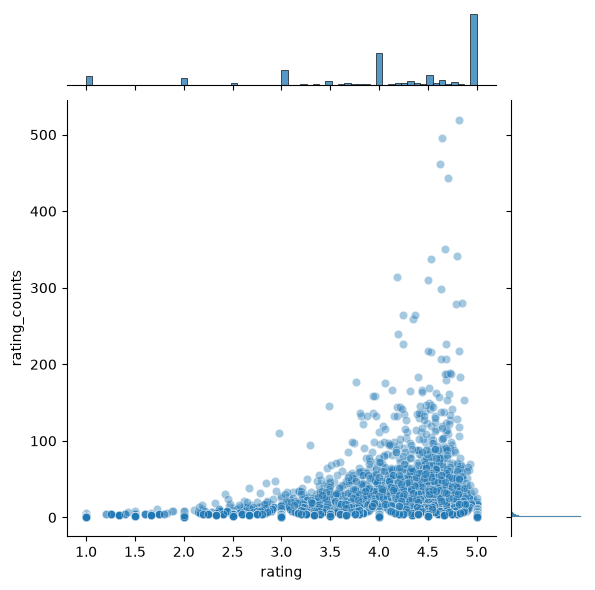

In [37]:
#From the joint plot below it seems that popular products (higher ratings) tend to be rated more frequently, majority have rated products in the higher range
#To make people more engaged (bottom of the chart) we can start by recommending them based on popularity based system and then
#slowly graduate them to collaborative system once we have sufficient number of data points to giver personlized recommendation
plt.figure(figsize=(8,6))
plt.rcParams['patch.force_edgecolor'] = True
sns.jointplot(x='rating', y='rating_counts', data=ratings_mean_count, alpha=0.4)

<Axes: xlabel='productId'>

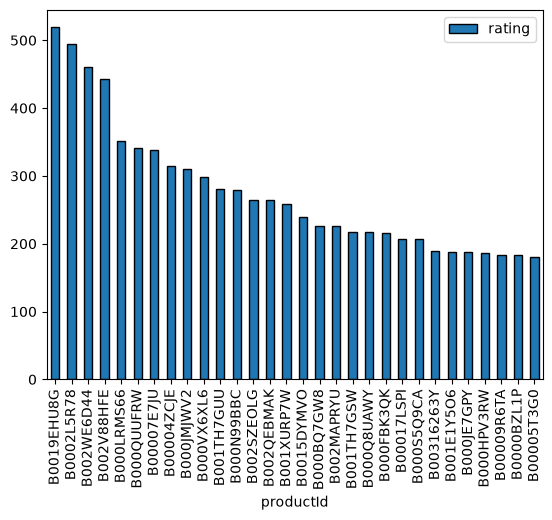

In [38]:
popular_products = pd.DataFrame(datasubset_final.groupby('productId')['rating'].count())
most_popular = popular_products.sort_values('rating', ascending=False)
most_popular.head(30).plot(kind = "bar")

In [39]:
no_of_ratings_per_user = datasubset_final.groupby(by='userId')['rating'].count().sort_values(ascending=False)

# Section - 3 (Contructing Pivot and Making The Model)

## 1. Constructing pivot table on `userId` and `productId` column based on the value of `ratings`


In [40]:
#constructing the pivot table
final_ratings_matrix = datasubset_final.pivot(index = 'userId', columns ='productId', values = 'rating').fillna(0)
final_ratings_matrix.head()

productId,0511189877,0594451647,0594481813,0970407998,0972683275,0979526191,1094441252,1254875778,1400501466,1400501520,...,B0031ESJ78,B0031ESKJ0,B0031ESKJA,B0031ESKRM,B0031ESTD2,B0031ESWP2,B0031ET9KO,B0031EUJXK,B0031GELCS,B0031GGQC6
userId,,,,,,,,,,,,,,,,,,,,,
A0655860XQH1M5Q8JH1M,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A10063PJ5C9WQQ,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A100H2245MF6NL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A100NGGXRQF0AQ,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A100UD67AHFODS,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


* It shows that it is a sparse matrix. So, many cells are filled with 0 values.

In [41]:
print('Shape of final_ratings_matrix: ', final_ratings_matrix.shape)

Shape of final_ratings_matrix:  (13808, 57394)


In [42]:
#Calucating the density of the rating marix
given_num_of_ratings = np.count_nonzero(final_ratings_matrix)
print('given_num_of_ratings = ', given_num_of_ratings)
possible_num_of_ratings = final_ratings_matrix.shape[0] * final_ratings_matrix.shape[1]
print('possible_num_of_ratings = ', possible_num_of_ratings)
density = (given_num_of_ratings/possible_num_of_ratings)
density *= 100
print ('density: {:4.2f}%'.format(density))

given_num_of_ratings =  224243
possible_num_of_ratings =  792496352
density: 0.03%


* The density value of the matrix also shows that it is a sparse matrix.

# 2. Splitting the data

In [75]:
#Split the data randomnly into train and test datasets into 70:30 ratio
train_data, test_data = train_test_split(datasubset_final, test_size = 0.3, random_state=42)
train_data.head()

,userId,productId,rating
1244292,AY7A86YCLB6WR,B000ODN7VM,1.0
630342,A245M6JE6I5B6O,B0007XJSQC,5.0
1332760,A3UM9V980DKANX,B000RMVIE8,5.0
1389021,A1WR0KA61A2CTW,B000UB7WD2,5.0
2796583,AQIJ3ZEEVCIKU,B002R5AM7C,3.0


In [76]:
print('Shape of training data: ',train_data.shape)
print('Shape of testing data: ',test_data.shape)

Shape of training data:  (156970, 3)
Shape of testing data:  (67273, 3)


In [84]:

def preference_based_recommendation(
    train_data, user_id, num_recommendations=5, k=20
):
    # 1. Create the user-item matrix using training data only
    user_item_matrix = train_data.pivot_table(
        index='userId',
        columns='productId',
        values='rating',
        aggfunc='mean',
        fill_value=0
    )

    # 2. Check whether the target user exists
    if user_id not in user_item_matrix.index:
        raise ValueError("User not found in training data.")

    # 3. Calculate cosine similarity between the target user
    # and all other users
    similarities = cosine_similarity(
        user_item_matrix.loc[[user_id]],
        user_item_matrix
    ).flatten()

    similarity_scores = pd.Series(
        similarities,
        index=user_item_matrix.index
    )

    # 4. Select the top k similar users, excluding the target
    similarity_scores = similarity_scores.drop(user_id)
    similar_users = similarity_scores[
        similarity_scores > 0
    ].nlargest(k)

    if similar_users.empty:
        return pd.DataFrame(
            columns=[
                'productId',
                'predicted_rating',
                'similar_users_count'
            ]
        )

    # 5. Find products the target user has not rated,
    # but at least one similar user has rated
    user_ratings = user_item_matrix.loc[user_id]

    neighbor_ratings = user_item_matrix.loc[similar_users.index]

    candidate_products = user_item_matrix.columns[
        (user_ratings == 0) &
        (neighbor_ratings > 0).any(axis=0)
    ]

    if len(candidate_products) == 0:
        return pd.DataFrame(
            columns=[
                'productId',
                'predicted_rating',
                'similar_users_count'
            ]
        )

    # 6. Keep ratings for candidate products only
    candidate_ratings = neighbor_ratings[candidate_products]

    # 7. Calculate similarity-weighted predicted ratings
    weighted_sum = candidate_ratings.mul(
        similar_users, axis=0
    ).sum(axis=0)

    # Ignore missing ratings when calculating the denominator
    weights_sum = candidate_ratings.gt(0).mul(
        similar_users, axis=0
    ).sum(axis=0)

    predicted_ratings = (
        weighted_sum / weights_sum.replace(0, np.nan)
    )

    # 8. Build the recommendation table
    recommendations = pd.DataFrame({
        'productId': predicted_ratings.index,
        'predicted_rating': predicted_ratings.values,
        'similar_users_count': candidate_ratings.gt(0).sum(axis=0).values
    })

    # 9. Rank products by predicted rating
    recommendations = recommendations.dropna(
        subset=['predicted_rating']
    )

    recommendations = recommendations.sort_values(
        'predicted_rating',
        ascending=False
    )

    return recommendations.head(num_recommendations).reset_index(drop=True)


In [85]:

# Select 3 random users from the training data
find_recom = train_data['userId'].drop_duplicates().sample(
    n=3, random_state=42
).tolist()

for user_id in find_recom:
    print(f"\nRecommendations for user: {user_id}")

    recommendations = preference_based_recommendation(
        train_data=train_data,
        user_id=user_id,
        num_recommendations=5,
        k=20
    )

    print(recommendations)



Recommendations for user: A2D8O4ANMAXKNX
    productId  predicted_rating  similar_users_count
0  B00004WLJ4               5.0                    1
1  B00005T39Y               5.0                    1
2  B00005UKBD               5.0                    1
3  B000067RRX               5.0                    1
4  B00006JPEV               5.0                    1

Recommendations for user: A39BW25SNOBOS5
    productId  predicted_rating  similar_users_count
0  140053271X               5.0                    1
1  B000062VUO               5.0                    1
2  B0002KRBH8               5.0                    1
3  B0006DPMUO               5.0                    1
4  B0002L5R78               5.0                    1

Recommendations for user: A3OU1OR3J7F9Y
    productId  predicted_rating  similar_users_count
0  B00005B8HO               5.0                    2
1  B000UV4EU6               5.0                    1
2  B0019UDB1A               5.0                    1
3  B0006HNHCA              

In [ ]:

# Build the training matrix and calculate similarities per user
# only once for this evaluation.

user_item_matrix = train_data.pivot_table(
    index='userId',
    columns='productId',
    values='rating',
    aggfunc='mean',
    fill_value=0
)

test_predictions = []
actual_ratings = []

for row in test_data.itertuples(index=False):
    user_id = row.userId
    product_id = row.productId
    actual_rating = row.rating

    # Skip users or products absent from training data
    if (user_id not in user_item_matrix.index or
        product_id not in user_item_matrix.columns):
        continue

    # Similarity of this user to all training users
    similarities = cosine_similarity(
        user_item_matrix.loc[[user_id]],
        user_item_matrix
    ).flatten()

    similarity_scores = pd.Series(
        similarities,
        index=user_item_matrix.index
    ).drop(user_id)

    similar_users = similarity_scores[
        similarity_scores > 0
    ].nlargest(20)

    if similar_users.empty:
        continue

    # Ratings from neighbors for this particular product
    neighbor_ratings = user_item_matrix.loc[
        similar_users.index, product_id
    ]

    # Use only neighbors who rated this product
    rated_mask = neighbor_ratings > 0
    neighbor_ratings = neighbor_ratings[rated_mask]
    neighbor_weights = similar_users.loc[neighbor_ratings.index]

    if neighbor_weights.sum() == 0:
        continue

    predicted_rating = (
        (neighbor_ratings * neighbor_weights).sum()
        / neighbor_weights.sum()
    )

    test_predictions.append(predicted_rating)
    actual_ratings.append(actual_rating)

if len(actual_ratings) > 0:
    mse = mean_squared_error(actual_ratings, test_predictions)
    rmse = np.sqrt(mse)

    print("Evaluated test ratings:", len(actual_ratings))
    print("User-based CF MSE:", mse)
    print("User-based CF RMSE:", rmse)
else:
    print("No eligible test ratings could be evaluated.")
